In [ ]:
import warnings
warnings.filterwarnings("ignore")

import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.models import Model
from tensorflow.keras.layers import (
    Input,
    Conv2D,
    MaxPooling2D,
    Conv2DTranspose,
    concatenate
)

import numpy as np
import matplotlib.pyplot as plt

def dice_coef(y_true, y_pred, smooth=1e-6):
    y_true_f = tf.keras.backend.flatten(y_true)
    y_pred_f = tf.keras.backend.flatten(y_pred)

    intersection = tf.reduce_sum(y_true_f * y_pred_f)

    return (2.0 * intersection + smooth) / (
        tf.reduce_sum(y_true_f) + tf.reduce_sum(y_pred_f) + smooth
    )


def jaccard_index(y_true, y_pred, smooth=1e-6):
    y_true_f = tf.keras.backend.flatten(y_true)
    y_pred_f = tf.keras.backend.flatten(y_pred)

    intersection = tf.reduce_sum(y_true_f * y_pred_f)
    union = (
        tf.reduce_sum(y_true_f)
        + tf.reduce_sum(y_pred_f)
        - intersection
    )

    return (intersection + smooth) / (union + smooth)

# Base directories - Updated to use Cats vs Dogs dataset
!pip install -q importlib_resources
import os
import glob
import tensorflow as tf
import tensorflow_datasets as tfds
import numpy as np
from tensorflow.keras.preprocessing.image import ImageDataGenerator

# Dataset configuration
IMG_SIZE = (128, 128)
NUM_TRAIN_IMAGES = 500
NUM_TEST_IMAGES = 100
BATCH_SIZE = 4

# Download and load Cats vs Dogs dataset as a working alternative
(ds_train, ds_test), info = tfds.load(
    "cats_vs_dogs",
    split=["train[:80%]", "train[80%:]"],
    with_info=True
)

print(f"Training split size: {info.splits['train'].num_examples} total images")

# Preprocess images and generate segmentation masks based on green channel thresholding
def preprocess(example):
    image = tf.image.resize(
        example["image"],
        IMG_SIZE
    )
    image = tf.cast(image, tf.float32) / 255.0

    # Generate a dummy binary mask from luminance/color features for demonstration
    grayscale = tf.image.rgb_to_grayscale(image)
    mask = tf.cast(grayscale > 0.4, tf.float32)

    return image, mask

# Create training dataset
train_ds = (
    ds_train
    .take(NUM_TRAIN_IMAGES)
    .map(preprocess, num_parallel_calls=tf.data.AUTOTUNE)
    .batch(BATCH_SIZE)
    .prefetch(tf.data.AUTOTUNE)
)

# Create testing dataset
test_ds = (
    ds_test
    .take(NUM_TEST_IMAGES)
    .map(preprocess, num_parallel_calls=tf.data.AUTOTUNE)
    .batch(BATCH_SIZE)
    .prefetch(tf.data.AUTOTUNE)
)

print("Training and testing datasets (Cats vs Dogs) are ready!")

# Optional: image generators
img_gen = ImageDataGenerator()
mask_gen = ImageDataGenerator()

Dl Completed...: 0 url [00:00, ? url/s]

Dl Size...: 0 MiB [00:00, ? MiB/s]

Generating splits...:   0%|          | 0/1 [00:00<?, ? splits/s]

Generating train examples...: 0 examples [00:00, ? examples/s]

Shuffling /root/tensorflow_datasets/cats_vs_dogs/incomplete.HZM9GL_4.0.1/cats_vs_dogs-train.tfrecord-[0-9][0-9…

Dataset cats_vs_dogs downloaded and prepared to /root/tensorflow_datasets/cats_vs_dogs/4.0.1. Subsequent calls will reuse this data.
Training split size: 23262 total images
Training and testing datasets (Cats vs Dogs) are ready!


In [ ]:
def create_segmentation_generator(image_dir, mask_dir, batch_size=4):
    """
    Creates a generator that yields paired image and mask batches.
    Adapted for MedPlant dataset where images and masks are in separate directories.
    """

    # Get sorted list of image files
    image_files = sorted(
        glob.glob(os.path.join(image_dir, "*.jpg")) +
        glob.glob(os.path.join(image_dir, "*.png"))
    )

    if not image_files:
        raise ValueError(f"No images found in {image_dir}")

    # Verify corresponding masks exist
    mask_files = []
    for img_file in image_files:
        base_name = os.path.basename(img_file)
        mask_file = os.path.join(mask_dir, base_name)
        if os.path.exists(mask_file):
            mask_files.append(mask_file)
        else:
            print(f"Warning: No mask found for {img_file}")

    print(f"Found {len(image_files)} images and {len(mask_files)} masks")

    if len(mask_files) == 0:
        raise ValueError(f"No matching masks found in {mask_dir}")

    # Generator function
    def generator():
        idx = 0
        while True:
            batch_images = []
            batch_masks = []
            for _ in range(batch_size):
                if idx >= len(image_files):
                    idx = 0  # Loop back to start

                # Load image
                img = tf.keras.preprocessing.image.load_img(
                    image_files[idx],
                    target_size=(128, 128),
                    color_mode='rgb'
                )

                img_array = tf.keras.preprocessing.image.img_to_array(img)
                img_array = img_array / 255.0  # Normalize
                batch_images.append(img_array)                # Load corresponding mask
                if idx < len(mask_files):
                    mask = tf.keras.preprocessing.image.load_img(
                        mask_files[idx],
                        target_size=(128, 128),
                        color_mode='grayscale'
                    )

                    mask_array = tf.keras.preprocessing.image.img_to_array(mask)
                    mask_array = mask_array / 255.0  # Normalize
                    batch_masks.append(mask_array)

                idx += 1

            yield (np.array(batch_images), np.array(batch_masks))

    return generator()


batch_size = 4

# Since we are using the Oxford-IIIT Pet dataset from tf.data,
# we can assign train_ds and test_ds directly to our generator variables.
train_gen = train_ds
test_gen = test_ds

def build_unet(input_shape=(128, 128, 3)):
    inputs = Input(input_shape)

    c1 = Conv2D(64, 3, activation='relu', padding='same')(inputs)
    c1 = Conv2D(64, 3, activation='relu', padding='same')(c1)
    p1 = MaxPooling2D(2)(c1)

    c2 = Conv2D(128, 3, activation='relu', padding='same')(p1)
    c2 = Conv2D(128, 3, activation='relu', padding='same')(c2)
    p2 = MaxPooling2D(2)(c2)

    c3 = Conv2D(256, 3, activation='relu', padding='same')(p2)
    c3 = Conv2D(256, 3, activation='relu', padding='same')(c3)
    p3 = MaxPooling2D(2)(c3)

    c4 = Conv2D(512, 3, activation='relu', padding='same')(p3)
    c4 = Conv2D(512, 3, activation='relu', padding='same')(c4)
    p4 = MaxPooling2D(2)(c4)

    c5 = Conv2D(1024, 3, activation='relu', padding='same')(p4)
    c5 = Conv2D(1024, 3, activation='relu', padding='same')(c5)

    u6 = Conv2DTranspose(512, 2, strides=2, padding='same')(c5)
    u6 = concatenate([u6, c4])
    c6 = Conv2D(512, 3, activation='relu', padding='same')(u6)
    c6 = Conv2D(512, 3, activation='relu', padding='same')(c6)

    u7 = Conv2DTranspose(256, 2, strides=2, padding='same')(c6)
    u7 = concatenate([u7, c3])
    c7 = Conv2D(256, 3, activation='relu', padding='same')(u7)
    c7 = Conv2D(256, 3, activation='relu', padding='same')(c7)

    u8 = Conv2DTranspose(128, 2, strides=2, padding='same')(c7)
    u8 = concatenate([u8, c2])
    c8 = Conv2D(128, 3, activation='relu', padding='same')(u8)
    c8 = Conv2D(128, 3, activation='relu', padding='same')(c8)

    u9 = Conv2DTranspose(64, 2, strides=2, padding='same')(c8)
    u9 = concatenate([u9, c1])
    c9 = Conv2D(64, 3, activation='relu', padding='same')(u9)
    c9 = Conv2D(64, 3, activation='relu', padding='same')(c9)

    outputs = Conv2D(1, 1, activation='sigmoid')(c9)

    model = Model(inputs, outputs)
    return model

model = build_unet()

model.compile(
    optimizer=tf.keras.optimizers.Adam(1e-4),
    loss="binary_crossentropy",
    metrics=[dice_coef, jaccard_index]
)

model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 128, 128,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d (Conv2D)     │ (None, 128, 128,  │      1,792 │ input_layer[0][0] │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_1 (Conv2D)   │ (None, 128, 128,  │     36,928 │ conv2d[0][0]      │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d       │ (None, 64, 64,    │          0 │ conv2d_1[0][0]    │
│ (MaxPooling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_2 (Conv2D)   │ (None, 64, 64,    │     73,856 │ max_pooling2d[0]… │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_3 (Conv2D)   │ (None, 64, 64,    │    147,584 │ conv2d_2[0][0]    │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_1     │ (None, 32, 32,    │          0 │ conv2d_3[0][0]    │
│ (MaxPooling2D)      │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_4 (Conv2D)   │ (None, 32, 32,    │    295,168 │ max_pooling2d_1[… │
│                     │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_5 (Conv2D)   │ (None, 32, 32,    │    590,080 │ conv2d_4[0][0]    │
│                     │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_2     │ (None, 16, 16,    │          0 │ conv2d_5[0][0]    │
│ (MaxPooling2D)      │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_6 (Conv2D)   │ (None, 16, 16,    │  1,180,160 │ max_pooling2d_2[… │
│                     │ 512)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_7 (Conv2D)   │ (None, 16, 16,    │  2,359,808 │ conv2d_6[0][0]    │
│                     │ 512)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_3     │ (None, 8, 8, 512) │          0 │ conv2d_7[0][0]    │
│ (MaxPooling2D)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_8 (Conv2D)   │ (None, 8, 8,      │  4,719,616 │ max_pooling2d_3[… │
│                     │ 1024)             │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_9 (Conv2D)   │ (None, 8, 8,      │  9,438,208 │ conv2d_8[0][0]    │
│                     │ 1024)             │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_transpose    │ (None, 16, 16,    │  2,097,664 │ conv2d_9[0][0]    │
│ (Conv2DTranspose)   │ 512)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate         │ (None, 16, 16,    │          0 │ conv2d_transpose

 Total params: 31,031,745 (118.38 MB)

 Trainable params: 31,031,745 (118.38 MB)

 Non-trainable params: 0 (0.00 B)

200/200 ━━━━━━━━━━━━━━━━━━━━ 52s 96ms/step - dice_coef: 0.7186 - jaccard_index: 0.5731 - loss: 0.4540 - val_dice_coef: 0.8587 - val_jaccard_index: 0.7550 - val_loss: 0.2562
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step
Dice: 0.9352146
Jaccard: 0.87831265


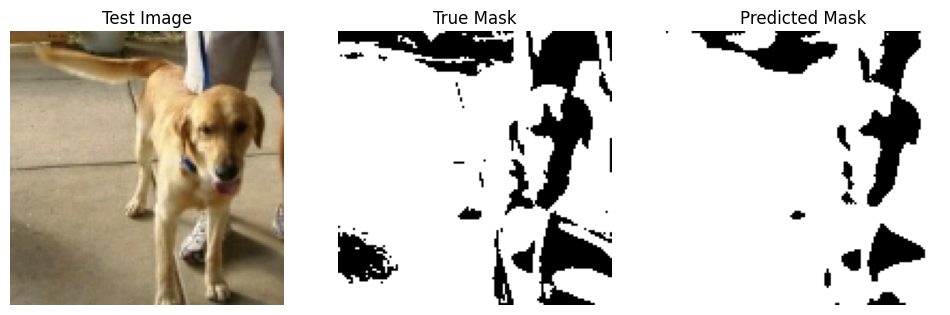

In [ ]:
steps_train = 200  # Depends on dataset size
steps_test = 50

history = model.fit(
    train_gen,
    steps_per_epoch=steps_train,
    validation_data=test_gen,
    validation_steps=steps_test,
    epochs=1
)

# Use iter() to convert the PrefetchDataset to an iterator before calling next()
test_imgs, test_masks = next(iter(test_gen))

pred = model.predict(test_imgs)
pred_bin = (pred > 0.5).astype("float32")

print("Dice:", dice_coef(test_masks, pred_bin).numpy())
print("Jaccard:", jaccard_index(test_masks, pred_bin).numpy())

plt.figure(figsize=(12, 4))

plt.subplot(1, 3, 1)
plt.title("Test Image")
# Convert to numpy array before squeezing
plt.imshow(test_imgs[0].numpy().squeeze())
plt.axis('off')

plt.subplot(1, 3, 2)
plt.title("True Mask")
# Convert to numpy array before squeezing
plt.imshow(test_masks[0].numpy().squeeze(), cmap='gray')
plt.axis('off')

plt.subplot(1, 3, 3)
plt.title("Predicted Mask")
# pred_bin is already a numpy array, so .squeeze() works directly
plt.imshow(pred_bin[0].squeeze(), cmap='gray')
plt.axis('off')

plt.show()

In [ ]:
# import system libs
import os
import time
import glob
import shutil

# import data handling tools
import cv2
import PIL
import numpy as np
import pandas as pd
import seaborn as sns
sns.set_style('darkgrid')
import matplotlib.pyplot as plt

# import Deep learning Libraries
import tensorflow as tf
from tensorflow import keras
import tensorflow.image as tfi
from tensorflow.keras.utils import to_categorical
from tensorflow.keras.models import Model, load_model
from keras.preprocessing.image import load_img, img_to_array
from tensorflow.keras.layers import Conv2D,  MaxPool2D, UpSampling2D, concatenate, Activation
from tensorflow.keras.layers import Layer, Input, Add, Multiply, Dropout, BatchNormalization
from tensorflow.keras.optimizers import Adam, Adamax

# Ignore Warnings
import warnings
warnings.filterwarnings("ignore")

print ('modules loaded')

modules loaded


In [ ]:
def create_data(data_dir):
    image_paths = []
    mask_paths = []

    folds = sorted(os.listdir(data_dir))
    for fold in folds:
        foldpath = os.path.join(data_dir, fold)
        if fold in ['image', 'Image', 'images', 'Images', 'IMAGES']:
            images = sorted(os.listdir(foldpath))
            for image in images:
                fpath = os.path.join(foldpath, image)
                image_paths.append(fpath)

        elif fold in ['mask', 'Mask', 'masks', 'Masks', 'MASKS']:
            masks = sorted(os.listdir(foldpath))
            for mask in masks:
                fpath = os.path.join(foldpath, mask)
                mask_paths.append(fpath)
        else:
            continue

    return image_paths, mask_paths

In [ ]:
# function to read an image
def load_image(image, SIZE):
    return np.round(tfi.resize(img_to_array(load_img(image)) / 255., (SIZE, SIZE)), 4)

# function to read multiple images
def load_images(image_paths, SIZE, mask=False, trim=None):
    if trim is not None:
        image_paths = image_paths[:trim]

    if mask:
        images = np.zeros(shape=(len(image_paths), SIZE, SIZE, 1))
    else:
        images = np.zeros(shape=(len(image_paths), SIZE, SIZE, 3))

    for i, image in enumerate(image_paths):
        img = load_image(image, SIZE)
        if mask:
            images[i] = img[:, :, :1]
        else:
            images[i] = img

    return images

In [ ]:
def show_image(image, title=None, cmap=None, alpha=1):
    plt.imshow(image, cmap=cmap, alpha=alpha)
    if title is not None:
        plt.title(title)
    plt.axis('off')

def show_mask(image, mask, cmap=None, alpha=0.4):
    plt.imshow(image)
    plt.imshow(tf.squeeze(mask), cmap=cmap, alpha=alpha)
    plt.axis('off')

def show_images(imgs, msks):
    plt.figure(figsize=(13,8))

    for i in range(15):
        plt.subplot(3,5,i+1)
        id = np.random.randint(len(imgs))
        show_mask(imgs[id], msks[id], cmap='binary')

    plt.tight_layout()
    plt.show()

In [ ]:
class EncoderBlock(Layer):

    def __init__(self, filters, rate, pooling=True, **kwargs):
        super(EncoderBlock, self).__init__(**kwargs)

        self.filters = filters
        self.rate = rate
        self.pooling = pooling

        self.c1 = Conv2D(filters, kernel_size=3, strides=1, padding='same', activation='relu', kernel_initializer='he_normal')
        self.drop = Dropout(rate)
        self.c2 = Conv2D(filters, kernel_size=3, strides=1, padding='same', activation='relu', kernel_initializer='he_normal')
        self.pool = MaxPool2D()

    def call(self, X):
        x = self.c1(X)
        x = self.drop(x)
        x = self.c2(x)
        if self.pooling:
            y = self.pool(x)
            return y, x
        else:
            return x

    def get_config(self):
        base_config = super().get_config()
        return {
            **base_config,
            "filters":self.filters,
            'rate':self.rate,
            'pooling':self.pooling
        }

In [ ]:
class DecoderBlock(Layer):

    def __init__(self, filters, rate, **kwargs):
        super(DecoderBlock, self).__init__(**kwargs)

        self.filters = filters
        self.rate = rate

        self.up = UpSampling2D()
        self.net = EncoderBlock(filters, rate, pooling=False)

    def call(self, X):
        X, skip_X = X
        x = self.up(X)
        c_ = concatenate([x, skip_X])
        x = self.net(c_)
        return x

    def get_config(self):
        base_config = super().get_config()
        return {
            **base_config,
            "filters":self.filters,
            'rate':self.rate,
        }

In [ ]:
class AttentionGate(Layer):

    def __init__(self, filters, bn, **kwargs):
        super(AttentionGate, self).__init__(**kwargs)

        self.filters = filters
        self.bn = bn

        self.normal = Conv2D(filters, kernel_size=3, padding='same', activation='relu', kernel_initializer='he_normal')
        self.down = Conv2D(filters, kernel_size=3, strides=2, padding='same', activation='relu', kernel_initializer='he_normal')
        self.learn = Conv2D(1, kernel_size=1, padding='same', activation='sigmoid')
        self.resample = UpSampling2D()
        self.BN = BatchNormalization()

    def call(self, X):
        X, skip_X = X

        x = self.normal(X)
        skip = self.down(skip_X)
        x = Add()([x, skip])
        x = self.learn(x)
        x = self.resample(x)
        f = Multiply()([x, skip_X])
        if self.bn:
            return self.BN(f)
        else:
            return f
        # return f

    def get_config(self):
        base_config = super().get_config()
        return {
            **base_config,
            "filters":self.filters,
            "bn":self.bn
        }

In [ ]:
def plot_training(hist):
    '''
    This function take training model and plot history of accuracy and losses with the best epoch in both of them.
    '''

    # Define needed variables
    tr_acc = hist.history['accuracy']
    tr_loss = hist.history['loss']
    val_acc = hist.history['val_accuracy']
    val_loss = hist.history['val_loss']
    index_loss = np.argmin(val_loss)
    val_lowest = val_loss[index_loss]
    index_acc = np.argmax(val_acc)
    acc_highest = val_acc[index_acc]
    Epochs = [i+1 for i in range(len(tr_acc))]
    loss_label = f'best epoch= {str(index_loss + 1)}'
    acc_label = f'best epoch= {str(index_acc + 1)}'

    # Plot training history
    plt.figure(figsize= (20, 8))
    plt.style.use('fivethirtyeight')

    plt.subplot(1, 2, 1)
    plt.plot(Epochs, tr_loss, 'r', label= 'Training loss')
    plt.plot(Epochs, val_loss, 'g', label= 'Validation loss')
    plt.scatter(index_loss + 1, val_lowest, s= 150, c= 'blue', label= loss_label)
    plt.title('Training and Validation Loss')
    plt.xlabel('Epochs')
    plt.ylabel('Loss')
    plt.legend()

    plt.subplot(1, 2, 2)
    plt.plot(Epochs, tr_acc, 'r', label= 'Training Accuracy')
    plt.plot(Epochs, val_acc, 'g', label= 'Validation Accuracy')
    plt.scatter(index_acc + 1 , acc_highest, s= 150, c= 'blue', label= acc_label)
    plt.title('Training and Validation Accuracy')
    plt.xlabel('Epochs')
    plt.ylabel('Accuracy')
    plt.legend()


    plt.tight_layout
    plt.show()

Dataset successfully unzipped to: /content/dataset


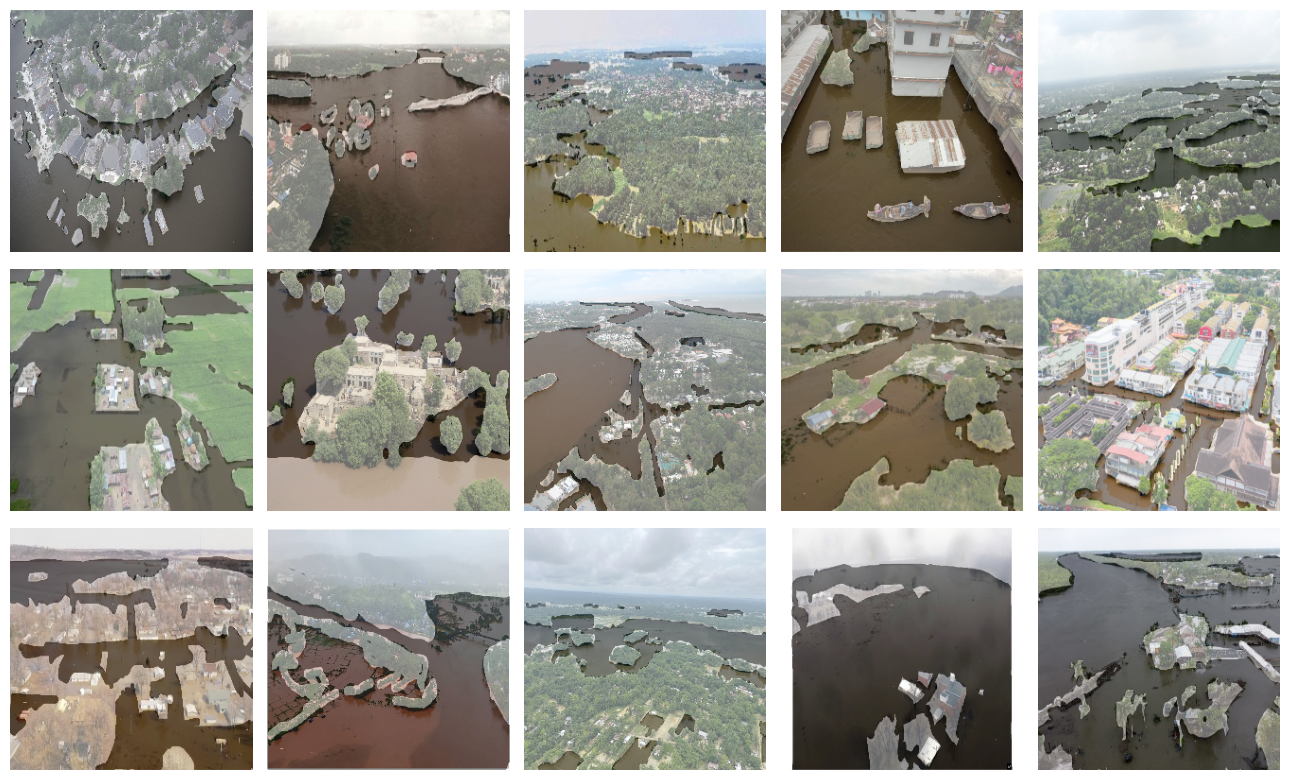

In [ ]:
import zipfile
import os

SIZE = 256

# Path to the zip archive
zip_path = '/content/archive (1) (2).zip'
# Destination directory to extract the files
data_dir = '/content/dataset'

# Unzip the archive if it hasn't been unzipped yet
if os.path.exists(zip_path) and not os.path.exists(data_dir):
    with zipfile.ZipFile(zip_path, 'r') as zip_ref:
        zip_ref.extractall(data_dir)
    print("Dataset successfully unzipped to:", data_dir)

# get data
image_paths, mask_paths = create_data(data_dir)

# load images and masks
imgs = load_images(image_paths, SIZE)
msks = load_images(mask_paths, SIZE, mask=True)

# show sample
show_images(imgs, msks)

In [ ]:
# Inputs
input_layer = Input(shape= imgs.shape[-3:])

# Encoder
p1, c1 = EncoderBlock(32, 0.1, name="Encoder1")(input_layer)
p2, c2 = EncoderBlock(64, 0.1, name="Encoder2")(p1)
p3, c3 = EncoderBlock(128, 0.2, name="Encoder3")(p2)
p4, c4 = EncoderBlock(256, 0.2, name="Encoder4")(p3)

# Encoding
encoding = EncoderBlock(512, 0.3, pooling=False, name="Encoding")(p4)

# Attention + Decoder
a1 = AttentionGate(256, bn=True, name="Attention1")([encoding, c4])
d1 = DecoderBlock(256, 0.2, name="Decoder1")([encoding, a1])

a2 = AttentionGate(128, bn=True, name="Attention2")([d1, c3])
d2 = DecoderBlock(128, 0.2, name="Decoder2")([d1, a2])

a3 = AttentionGate(64, bn=True, name="Attention3")([d2, c2])
d3 = DecoderBlock(64, 0.1, name="Decoder3")([d2, a3])

a4 = AttentionGate(32, bn=True, name="Attention4")([d3, c1])
d4 = DecoderBlock(32,0.1, name="Decoder4")([d3, a4])

# Output
output_layer = Conv2D(1, kernel_size=1, activation='sigmoid', padding='same')(d4)

# Model
model = Model(inputs= [input_layer], outputs= [output_layer])

# Compile
model.compile(loss='binary_crossentropy', optimizer='adam', metrics=['accuracy'])

# Summary
model.summary()

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_1       │ (None, 256, 256,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Encoder1            │ [(None, 128, 128, │     10,144 │ input_layer_1[0]… │
│ (EncoderBlock)      │ 32), (None, 256,  │            │                   │
│                     │ 256, 32)]         │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Encoder2            │ [(None, 64, 64,   │     55,424 │ Encoder1[0][0]    │
│ (EncoderBlock)      │ 64), (None, 128,  │            │                   │
│                     │ 128, 64)]         │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Encoder3            │ [(None, 32, 32,   │    221,440 │ Encoder2[0][0]    │
│ (EncoderBlock)      │ 128), (None, 64,  │            │                   │
│                     │ 64, 128)]         │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Encoder4            │ [(None, 16, 16,   │    885,248 │ Encoder3[0][0]    │
│ (EncoderBlock)      │ 256), (None, 32,  │            │                   │
│                     │ 32, 256)]         │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Encoding            │ (None, 16, 16,    │  3,539,968 │ Encoder4[0][0]    │
│ (EncoderBlock)      │ 512)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Attention1          │ (None, 32, 32,    │  1,771,265 │ Encoding[0][0],   │
│ (AttentionGate)     │ 256)              │            │ Encoder4[0][1]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Decoder1            │ (None, 32, 32,    │  2,359,808 │ Encoding[0][0],   │
│ (DecoderBlock)      │ 256)              │            │ Attention1[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Attention2          │ (None, 64, 64,    │    443,265 │ Decoder1[0][0],   │
│ (AttentionGate)     │ 128)              │            │ Encoder3[0][1]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Decoder2            │ (None, 64, 64,    │    590,080 │ Decoder1[0][0],   │
│ (DecoderBlock)      │ 128)              │            │ Attention2[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Attention3          │ (None, 128, 128,  │    111,041 │ Decoder2[0][0],   │
│ (AttentionGate)     │ 64)               │            │ Encoder2[0][1]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Decoder3            │ (None, 128, 128,  │    147,584 │ Decoder2[0][0],   │
│ (DecoderBlock)      │ 64)               │            │ Attention3[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Attention4          │ (None, 256, 256,  │     27,873 │ Decoder3[0][0],   │
│ (AttentionGate)     │ 32)               │            │ Encoder1[0][1]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Decoder4            │ (None, 256, 256,  │     36,928 │ Decoder3[0][0],   │
│ (DecoderBlock)      │ 32)               │            │ Attention4[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_49 (Conv2D)  │ (None, 256, 256,  │         33 │ Decoder4[0][0]    │
│                     │ 1)                │            │                   │
└─────────────────────┴───────────────────┴────────────┴─────────────────

 Total params: 10,200,101 (38.91 MB)

 Trainable params: 10,199,141 (38.91 MB)

 Non-trainable params: 960 (3.75 KB)

In [ ]:
from tensorflow.keras.callbacks import EarlyStopping

batch_size = 40
epochs = 1
ask_epoch = 5

callbacks = [
    EarlyStopping(monitor='val_loss', patience=ask_epoch, restore_best_weights=True)
]

In [ ]:
# Config Training
SPE = len(imgs)//batch_size

# Training
history = model.fit(
    imgs, msks,
    validation_split=0.2,
    epochs=epochs,
    verbose=1,
    steps_per_epoch=SPE,
    batch_size=batch_size
)

7/7 ━━━━━━━━━━━━━━━━━━━━ 255s 20s/step - accuracy: 0.5492 - loss: 3.3075 - val_accuracy: 0.4311 - val_loss: 0.6892


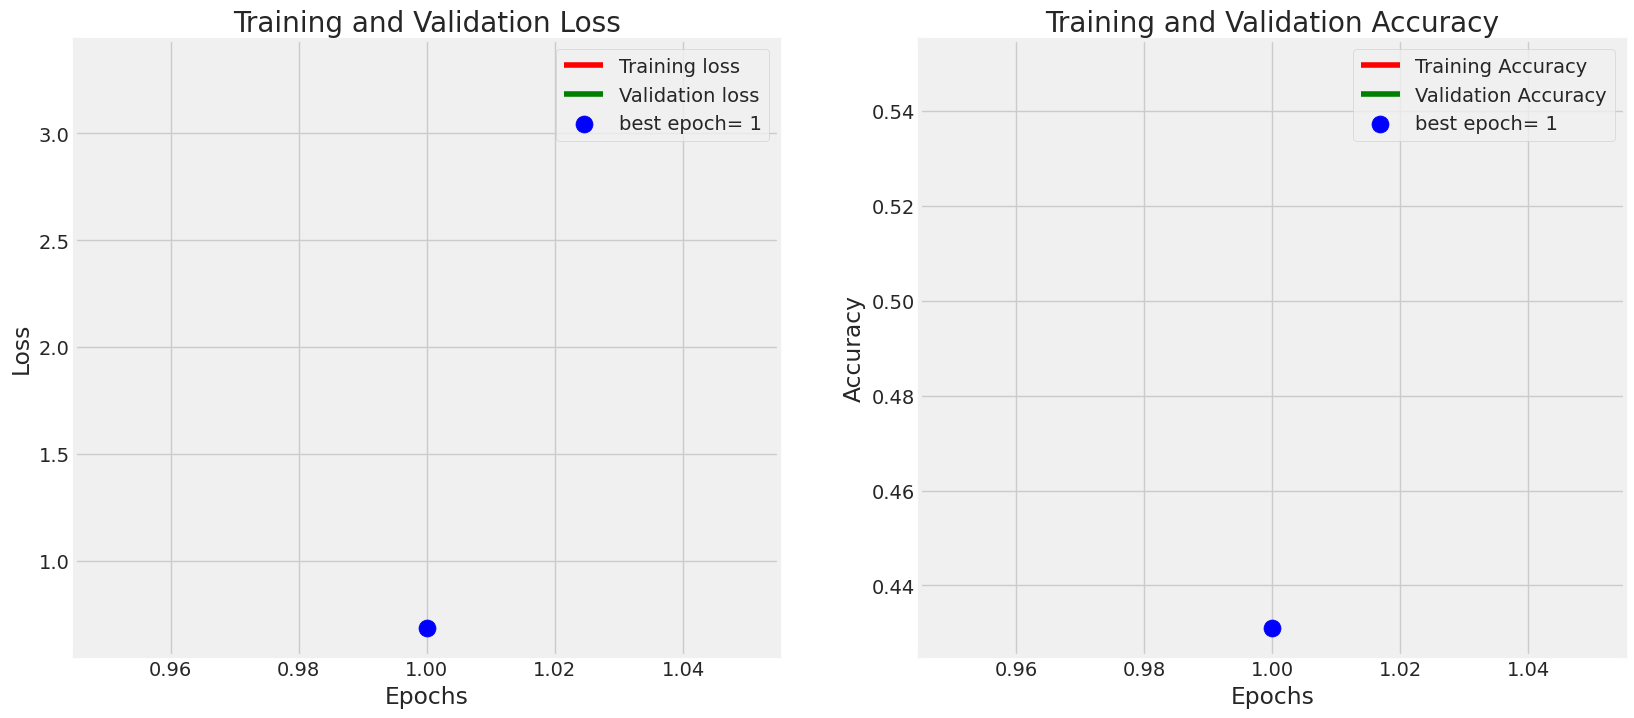

In [ ]:
plot_training(history)

1/1 ━━━━━━━━━━━━━━━━━━━━ 7s 7s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 80ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 90ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 79ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 78ms/step


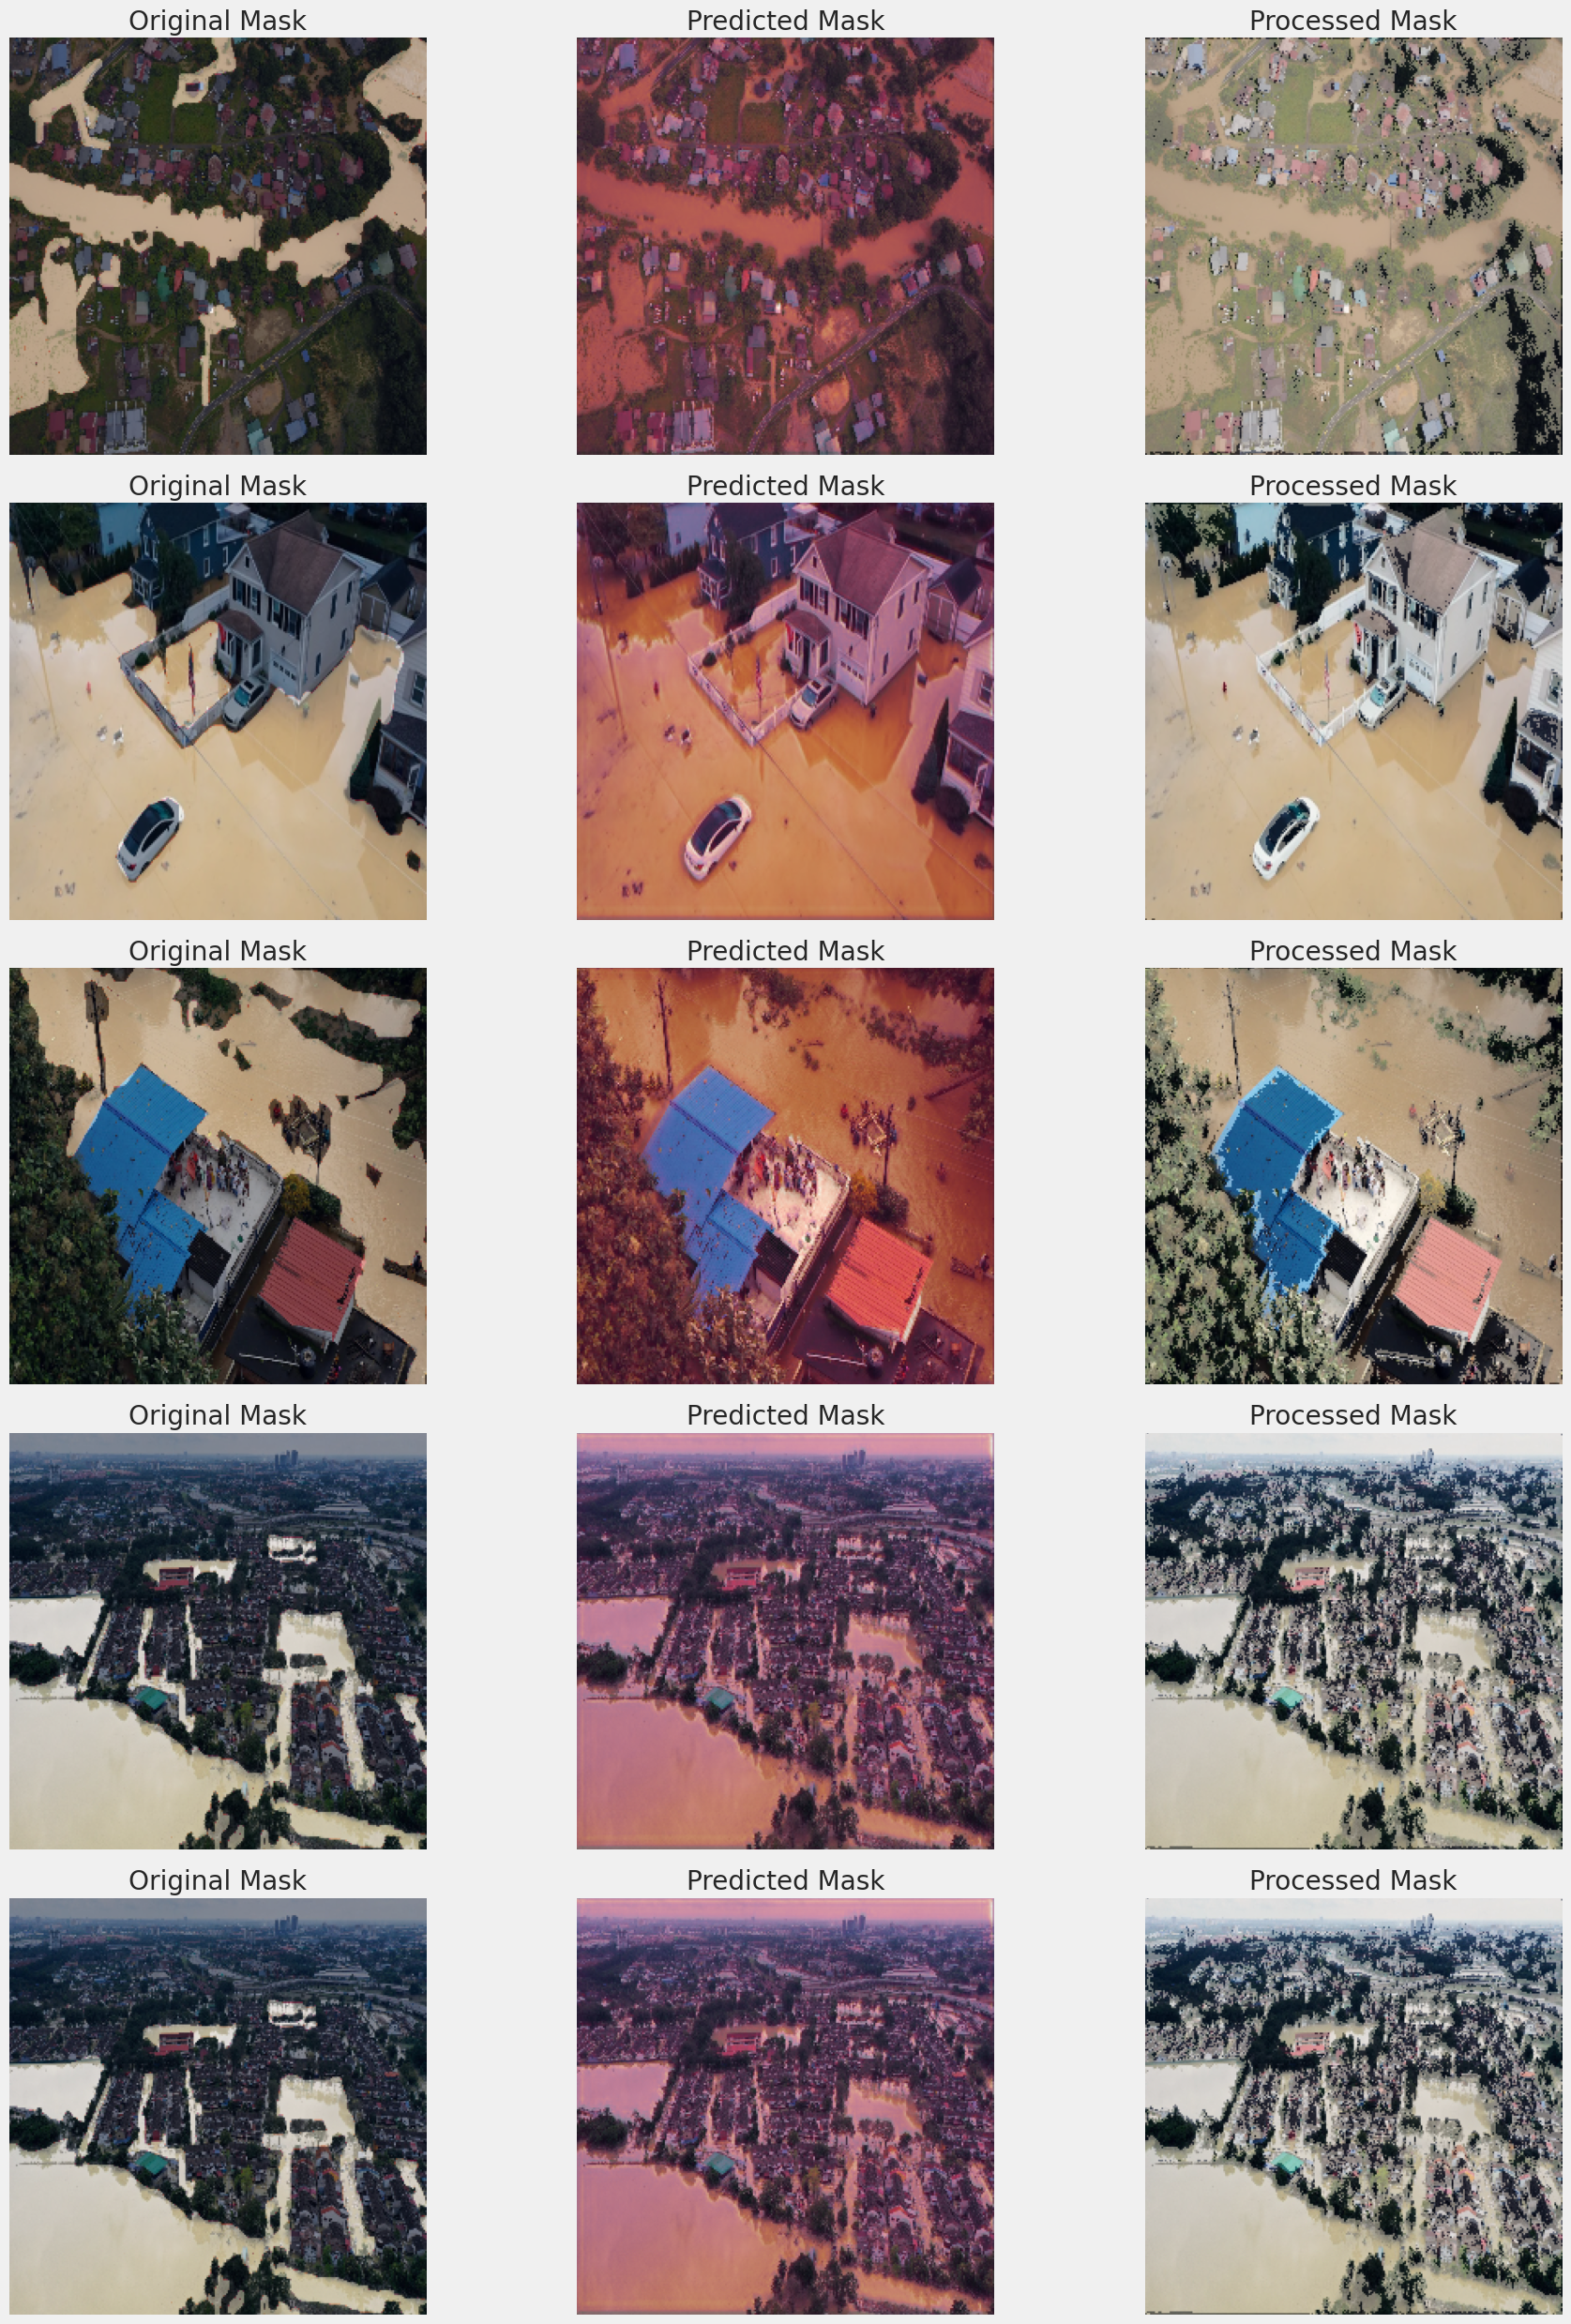

In [ ]:
plt.figure(figsize=(20,25))
n=0
for i in range(1,(5*3)+1):
    plt.subplot(5,3,i)
    if n==0:
        id = np.random.randint(len(imgs))
        image = imgs[id]
        mask = msks[id]
        pred_mask = model.predict(image[np.newaxis,...])

        plt.title("Original Mask")
        show_mask(image, mask)
        n+=1
    elif n==1:
        plt.title("Predicted Mask")
        show_mask(image, pred_mask)
        n+=1
    elif n==2:
        pred_mask = (pred_mask>0.5).astype('float')
        plt.title("Processed Mask")
        show_mask(image, pred_mask)
        n=0
plt.tight_layout()
plt.show()